# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:**Amara latif
- **Student ID:** 023-24-0012
- **Section:**B
- **GitHub:**
- **Kaggle:**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [3]:
# YOUR CODE HERE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_samples
from sklearn.metrics import adjusted_rand_score

# Set random seed
SEED = 42

print("All libraries imported successfully!")
print("Random Seed:", SEED)


All libraries imported successfully!
Random Seed: 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [4]:
# YOUR CODE HERE

# Task 0.1 - Load and Check the Data

# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

# Rename columns
df.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
}, inplace=True)

# 1. Print dataset shape
print("Dataset Shape:")
print(df.shape)

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 4. Count each Gender
print("\nGender Counts:")
print(df['Gender'].value_counts())

# 5. Statistical description
print("\nStatistical Description:")
print(df[['Age', 'Income', 'Spending']].describe())


Dataset Shape:
(200, 5)

Missing Values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate Rows:
0

Gender Counts:
Gender
Female    112
Male       88
Name: count, dtype: int64

Statistical Description:
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


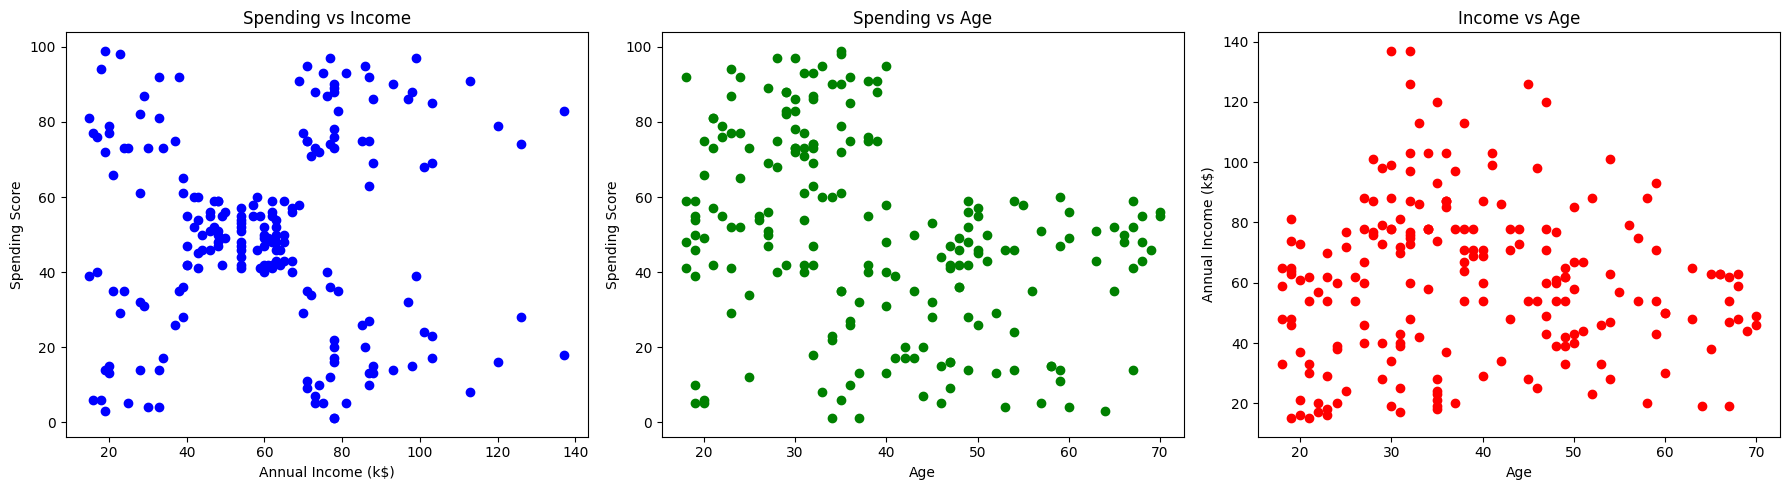

In [5]:
# YOUR CODE HERE

# Task 0.2 - Three Scatter Plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Spending vs Income
axes[0].scatter(df['Income'], df['Spending'], color='blue')
axes[0].set_title('Spending vs Income')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score')

# Plot 2: Spending vs Age
axes[1].scatter(df['Age'], df['Spending'], color='green')
axes[1].set_title('Spending vs Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score')

# Plot 3: Income vs Age
axes[2].scatter(df['Age'], df['Income'], color='red')
axes[2].set_title('Income vs Age')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Annual Income (k$)')

plt.tight_layout()
plt.show()


**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a)
Spending vs Income: Approximately 5 groups can be observed.
Spending vs Age: The groups are less clearly separated.
Income vs Age: The groups are also less clearly separated.
The Spending vs Income plot shows the groups most clearly because customers with different income and spending scores form visible groups. This makes it useful for K-Means clustering.


(b)
We cannot use accuracy or a train/test split because K-Means is an unsupervised learning algorithm. The dataset does not contain a target column or predefined correct labels. K-Means discovers groups automatically based on similarities and distances between data points.
Therefore, we evaluate clustering using distance, inertia, silhouette score, plots and common sense instead of accuracy.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [7]:
# YOUR CODE HERE
# Given data
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

# Initial centroids
m = np.array([4.0, 11.0])

iteration = 0

while True:
    iteration += 1

    # Calculate distances
    dist = np.abs(x[:, None] - m[None, :])

    # Assign points to nearest centroid
    labels = dist.argmin(axis=1)

    # Update centroids
    new_m = np.array([
        x[labels == k].mean() if np.any(labels == k) else m[k]
        for k in range(2)
    ])

    # Print clusters and centroids
    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster C{k+1}: {x[labels == k]}")

    print("New Centroids:", new_m)

    # Check convergence
    if np.allclose(new_m, m):
        m = new_m
        break

    m = new_m

# Calculate final inertia
inertia = np.sum((x - m[labels]) ** 2)

print("\nFinal Centroids:", m)
print("Final Inertia:", inertia)
print("Total Iterations:", iteration)



Iteration 1
Cluster C1: [2 4 3]
Cluster C2: [10 12 20 30 11 25]
New Centroids: [ 3. 18.]

Iteration 2
Cluster C1: [ 2  4 10  3]
Cluster C2: [12 20 30 11 25]
New Centroids: [ 4.75 19.6 ]

Iteration 3
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New Centroids: [ 7. 25.]

Iteration 4
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New Centroids: [ 7. 25.]

Final Centroids: [ 7. 25.]
Final Inertia: 150.0
Total Iterations: 4


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [8]:
# YOUR CODE HERE
X = np.array([
    [185, 72],  # P1
    [170, 56],  # P2
    [168, 60],  # P3
    [179, 68],  # P4
    [182, 72],  # P5
    [188, 77]   # P6
], dtype=float)

# Starting centroids: P1 and P2
centroids = X[[0, 1]].copy()

print("Starting centroids:")
print(centroids)





iteration = 0
while True:
    iteration += 1

    # 1. Calculate Euclidean distances
    dist = np.sqrt(
        ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
    )

    # 2. Assign points to nearest centroid
    labels = dist.argmin(axis=1)

    # 3. Update centroids
    new_centroids = np.array([
        X[labels == k].mean(axis=0) for k in range(2)
    ])

    # 4. Print clusters
    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k + 1}:")
        for i in range(len(X)):
            if labels[i] == k:
                print(f"P{i + 1}: {X[i]}")

    print("New centroids:")
    print(new_centroids)

    # 5. Stop when centroids do not change
    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids





    final_dist = np.sqrt(
    ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
)
distance_table = pd.DataFrame(
    final_dist,
    columns=["Distance to M1", "Distance to M2"],
    index=[f"P{i+1}" for i in range(len(X))]
)
print("Final centroids:")
print(centroids)

print("\nFinal distance table:")
print(distance_table.round(2))






P3 = X[2]
M2 = X[1]
distance = np.sqrt(np.sum((P3 - M2) ** 2))
print("P3:", P3)
print("M2:", M2)
print("Distance P3 to M2:", round(distance, 2))

Starting centroids:
[[185.  72.]
 [170.  56.]]

Iteration 1
Cluster 1:
P1: [185.  72.]
P4: [179.  68.]
P5: [182.  72.]
P6: [188.  77.]
Cluster 2:
P2: [170.  56.]
P3: [168.  60.]
New centroids:
[[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster 1:
P1: [185.  72.]
P4: [179.  68.]
P5: [182.  72.]
P6: [188.  77.]
Cluster 2:
P2: [170.  56.]
P3: [168.  60.]
New centroids:
[[183.5   72.25]
 [169.    58.  ]]
Final centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final distance table:
    Distance to M1  Distance to M2
P1            1.52           21.26
P2           21.13            2.24
P3           19.76            2.24
P4            6.19           14.14
P5            1.52           19.10
P6            6.54           26.87
P3: [168.  60.]
M2: [170.  56.]
Distance P3 to M2: 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [9]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):

    # Convert inputs to NumPy arrays
    X = np.array(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float).copy()

    for iteration in range(1, max_iter + 1):

        # 1. Calculate Euclidean distances
        dist = np.sqrt(
            ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
        )

        # 2. Assign each point to nearest centroid
        labels = dist.argmin(axis=1)

        # 3. Update centroids
        new_centroids = centroids.copy()

        for k in range(len(centroids)):

            # If cluster is not empty, calculate its mean
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)

            # If cluster is empty, keep its old centroid

        # 4. Check convergence
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    # Reassign points using final centroids
    final_dist = np.sqrt(
        ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
    )
    labels = final_dist.argmin(axis=1)

    # 5. Calculate inertia
    inertia = np.sum((X - centroids[labels]) ** 2)

    return labels, centroids, inertia, iteration

In [10]:
# YOUR CODE HERE

# Example 1
X1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25]).reshape(-1, 1)

# Initial centroids: 4 and 11
init_centroids = np.array([[4], [11]])

# Run our function
labels, final_centroids, inertia, iterations = my_kmeans(
    X1,
    init_centroids
)

print("Cluster labels:", labels)
print("Final centroids:", final_centroids.flatten())
print("Inertia:", inertia)
print("Iterations:", iterations)


# For verify.
assert np.allclose(final_centroids.flatten(), [7, 25])
assert np.isclose(inertia, 150)

print("All tests passed!")


# "If a cluster becomes empty, we keep its previous centroid unchanged."
# " This prevents errors when calculating the mean of an empty cluster and allows the K-Means algorithm to continue running."

Cluster labels: [0 0 0 0 0 1 1 0 1]
Final centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4
All tests passed!


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [11]:
# YOUR CODE HERE
# Select Income and Spending features
X2 = df[['Income', 'Spending']].values

# Take first 5 rows as starting centroids
init_centroids = X2[:5].copy()
print("Data shape:", X2.shape)
print("\nInitial centroids:")
print(init_centroids)



# 2
# Run our own K-Means function
my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2, init_centroids
)

# Run Scikit-learn KMeans
sk_model = KMeans(
    n_clusters=5,
    init=init_centroids,
    n_init=1,
    tol=0,
    algorithm='lloyd'
)

sk_model.fit(X2)

# Print comparison
print("My K-Means:")
print("Iterations:", my_iterations)
print("Inertia:", my_inertia)
print("Centroids:\n", my_centroids)

print("\nScikit-learn KMeans:")
print("Iterations:", sk_model.n_iter_)
print("Inertia:", sk_model.inertia_)
print("Centroids:\n", sk_model.cluster_centers_)


# 3 
print("Iterations match:",
      my_iterations == sk_model.n_iter_)

print("Inertia match:",
      np.isclose(my_inertia, sk_model.inertia_))

print("Centroids match:",
      np.allclose(my_centroids, sk_model.cluster_centers_))

print("Labels match:",
      np.array_equal(my_labels, sk_model.labels_))

print("Adjusted Rand Score:",
      adjusted_rand_score(my_labels, sk_model.labels_))


Data shape: (200, 2)

Initial centroids:
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]
My K-Means:
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

Scikit-learn KMeans:
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]
Iterations match: True
Inertia match: True
Centroids match: True
Labels match: True
Adjusted Rand Score: 1.0


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a)In the beginning, centroids were 4 and 11. Point 10 was closer to centroid 11, so it was assigned to C2.
Ans:    After iteration 1, the new centroids became 3 and 18. Now the distance of point 10 from centroid 3 is 7, and from centroid 18 is 8. Therefore, point 10 moved to C1 in iteration 2.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?
Ans:    The loop stops when the centroids no longer change. We use np.allclose() to check whether the old and new centroids are approximately equal.
K-Means has a finite number of possible cluster assignments, and each iteration does not increase inertia. Therefore, it eventually converges to a solution, although that solution may be a local minimum rather than the global best solution.


(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.
Ans:    Yes, my function matched scikit-learn. Both produced the same labels, centroids and inertia. The Adjusted Rand Score was 1.0.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?
Ans:    A centroid represents the average characteristics of customers in a cluster. For example, it can represent the average annual income and average spending score of a customer group.
Features must be numeric because K-Means calculates distances and averages mathematically. Text or categorical values cannot be directly used in Euclidean distance calculations.   

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


    K     Inertia  Silhouette
0   2  181363.596       0.297
1   3  106348.373       0.468
2   4   73679.789       0.493
3   5   44448.455       0.554
4   6   37233.815       0.540
5   7   30241.344       0.529
6   8   25036.418       0.455
7   9   21916.795       0.456
8  10   20072.071       0.441
KMeans Evaluation Results:


,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


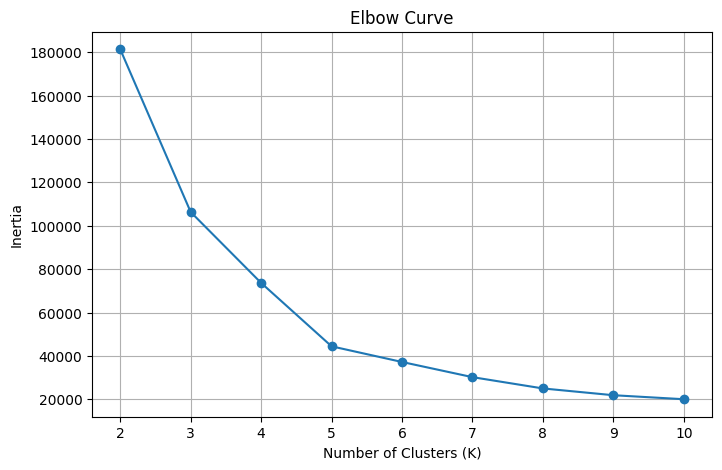

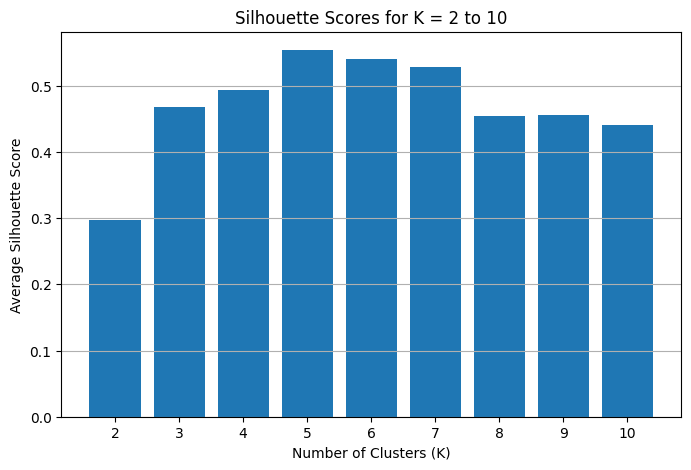

K with the highest silhouette score: 5


In [26]:
# YOUR CODE HERE
results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    labels = model.fit_predict(X2)

    inertia = model.inertia_
    silhouette = silhouette_score(X2, labels)

    results.append([k, inertia, silhouette])

# Display results in table
results_df = pd.DataFrame(
    results,
    columns=['K', 'Inertia', 'Silhouette']
)

print(results_df.round(3))





# 2
# Display K, Inertia, and Silhouette table
print("KMeans Evaluation Results:")
display(results_df.round(4))

# Plot 1: Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(
    results_df['K'],
    results_df['Inertia'],
    marker='o'
)
plt.title('Elbow Curve')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

# Plot 2: Silhouette Bars
plt.figure(figsize=(8, 5))
plt.bar(
    results_df['K'],
    results_df['Silhouette']
)
plt.title('Silhouette Scores for K = 2 to 10')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(axis='y')
plt.show()






# 3
# Find K with the highest silhouette score
best_k = results_df.loc[
    results_df['Silhouette'].idxmax(), 'K'
]

print("K with the highest silhouette score:", best_k)



### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

# Select features
X = df[['Income', 'Spending']].to_numpy()

# Fit KMeans with 5 clusters
kmeans = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels = kmeans.fit_predict(X)

# Manual silhouette function
def calculate_silhouette(X, labels, point_index):

    point = X[point_index]
    own_cluster = labels[point_index]

    distances = np.sqrt(np.sum((X - point) ** 2, axis=1))

    # Calculate a
    same_cluster = labels == own_cluster
    same_cluster[point_index] = False
    a = np.mean(distances[same_cluster])

    # Calculate b
    other_clusters = np.unique(labels[labels != own_cluster])

    average_distances = []

    for cluster in other_clusters:
        cluster_points = labels == cluster
        average_distances.append(
            np.mean(distances[cluster_points])
        )

    b = np.min(average_distances)

    # Calculate s
    s = (b - a) / max(a, b)

    return a, b, s


# Customer 1 (row 0)
a, b, s = calculate_silhouette(X, labels, 0)

silhouette_values = silhouette_samples(X, labels)

print("Customer 1 (Row 0)")
print("a =", a)
print("b =", b)
print("Manual silhouette =", s)
print("Sklearn silhouette =", silhouette_values[0])
print("Difference =", abs(s - silhouette_values[0]))


Customer 1 (Row 0)
a = 24.64044215163639
b = 42.26526678748377
Manual silhouette = 0.41700493041881637
Sklearn silhouette = 0.4170049304188163
Difference = 5.551115123125783e-17


Silhouette Statistics by Cluster:


,Count,Mean_Silhouette,Minimum_Silhouette
Cluster,,,
0,81,0.5967,0.1153
1,39,0.5092,0.2254
2,22,0.5990,0.0507
3,35,0.5040,-0.0234
4,23,0.5123,-0.0093


Number of customers with negative silhouette: 2


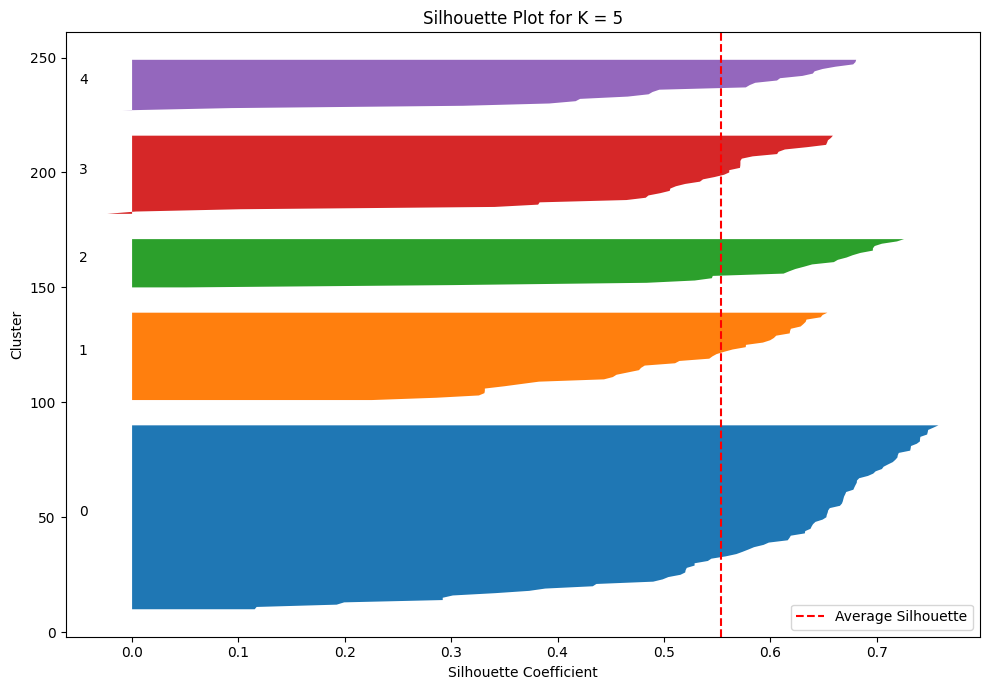

In [32]:
# YOUR CODE HERE
# part2
silhouette_df = pd.DataFrame({
    'Cluster': labels,
    'Silhouette': silhouette_values
})

cluster_summary = silhouette_df.groupby('Cluster').agg(
    Count=('Silhouette', 'count'),
    Mean_Silhouette=('Silhouette', 'mean'),
    Minimum_Silhouette=('Silhouette', 'min')
)

print("Silhouette Statistics by Cluster:")
display(cluster_summary.round(4))

negative_count = np.sum(silhouette_values < 0)

print("Number of customers with negative silhouette:",
      negative_count)



# part 3
fig, ax = plt.subplots(figsize=(10, 7))
y_lower = 10
for i in range(5):
    cluster_silhouette = silhouette_values[labels == i]
    cluster_silhouette.sort()
    size_cluster = len(cluster_silhouette)
    y_upper = y_lower + size_cluster

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_silhouette
    )

    ax.text(-0.05, y_lower + 0.5 * size_cluster, str(i))
    y_lower = y_upper + 10

average_silhouette = np.mean(silhouette_values)
ax.axvline(
    x=average_silhouette,
    color='red',
    linestyle='--',
    label='Average Silhouette'
)
ax.set_title('Silhouette Plot for K = 5')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster')
ax.legend()
plt.tight_layout()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [ ]:
# YOUR CODE HERE
import numpy as np
# Given points
X_practice = np.array([1, 3, 5, 7, 11, 13, 15]).reshape(-1, 1)

# Starting centroids
initial_centroids = np.array([[1], [11]])

# My KMeans function
def my_kmeans(X, initial_centroids, max_iter=100):

    centroids = initial_centroids.copy()
    iterations = []

    for iteration in range(max_iter):

        # Calculate distances
        distances = np.sqrt(
            np.sum((X[:, np.newaxis] - centroids) ** 2, axis=2)
        )

        # Assign points to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Update centroids
        new_centroids = np.array([
            X[labels == k].mean(axis=0)
            for k in range(len(centroids))
        ])

        iterations.append({
            'Iteration': iteration + 1,
            'Clusters': [
                X[labels == k].flatten().tolist()
                for k in range(len(centroids))
            ],
            'Centroids': new_centroids.flatten().tolist()
        })

        # Stop if centroids do not change
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    return labels, centroids, iterations


# Run my_kmeans
labels_practice, final_centroids, iterations = my_kmeans(
    X_practice,
    initial_centroids
)

# Print final results
print("Final Clusters:")

for k in range(2):
    print(
        f"Cluster {k+1}:",
        X_practice[labels_practice == k].flatten()
    )

print("\nFinal Centroids:")
print(final_centroids.flatten())

print("\nNumber of Iterations:")
print(len(iterations))



# part2

from sklearn.metrics import silhouette_samples

def calculate_silhouette(X, labels, point_index):

    point = X[point_index]
    own_cluster = labels[point_index]

    # Calculate Euclidean distances using NumPy
    distances = np.sqrt(
        np.sum((X - point) ** 2, axis=1)
    )

    # Calculate a: average distance within own cluster
    same_cluster = labels == own_cluster
    same_cluster[point_index] = False

    a = np.mean(distances[same_cluster])

    # Calculate b: minimum average distance to another cluster
    other_clusters = np.unique(labels[labels != own_cluster])

    average_distances = []

    for cluster in other_clusters:
        cluster_points = labels == cluster
        average_distances.append(
            np.mean(distances[cluster_points])
        )

    b = np.min(average_distances)

    # Calculate silhouette
    s = (b - a) / max(a, b)

    return a, b, s


# Calculate sklearn silhouette scores
sklearn_scores = silhouette_samples(
    X_practice,
    labels_practice
)

# Points to test: 1, 7 and 11
test_points = [1, 7, 11]

print("Silhouette Comparison:\n")

for point_value in test_points:

    index = np.where(X_practice.flatten() == point_value)[0][0]

    a, b, s = calculate_silhouette(
        X_practice,
        labels_practice,
        index
    )

    print("Point:", point_value)
    print("a =", a)
    print("b =", b)
    print("Manual Silhouette =", s)
    print("Sklearn Silhouette =", sklearn_scores[index])
    print("--------------------------")



Final Clusters:
Cluster 1: [1 3 5 7]
Cluster 2: [11 13 15]

Final Centroids:
[ 4. 13.]

Number of Iterations:
3


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



Customer 1 silhouette: 0.4170049304188163

Cluster statistics:


,Count,Mean_Silhouette,Minimum_Silhouette
Cluster,,,
0,81,0.5967,0.1153
1,39,0.5092,0.2254
2,22,0.5990,0.0507
3,35,0.5040,-0.0234
4,23,0.5123,-0.0093



Negative silhouette customers: 2


**Your answers:**

(a)The elbow method suggests K = 5 because the reduction in inertia starts slowing down after five clusters. The inertia decreases by 29,231.33 from K=4 to K=5 and by 7,214.64 from K=5 to K=6. The silhouette method also suggests K = 5, with the highest silhouette score of 0.5539. Therefore, both methods agree that 5 is the optimal number of customer groups.

(b) Customer 1 has a silhouette score of 0.4170, which indicates that the customer is reasonably well placed in its assigned cluster, although there is some overlap with other clusters.
Cluster 3 has the weakest average silhouette score of 0.5040. There are 2 customers with negative silhouette values, indicating that they may be assigned to the wrong clusters.
Overall, the clustering results show reasonably good separation between the five customer groups.

(c) Point 7 is less well placed than point 1. For point 1, the average distance within its own cluster is a = 3, while the minimum average distance to another cluster is b = 10.5. Its silhouette score is 0.7143, indicating that it is well placed in its cluster.
For point 7, a = 6 and b = 4. Its silhouette score is -0.3333, which indicates that it is closer to another cluster than to its assigned cluster. Therefore, point 7 is less well placed and may be incorrectly assigned.

(d) We should never choose K only by the lowest inertia because inertia always decreases when the number of clusters increases. If we choose the lowest inertia, we might select too many clusters, even if they do not represent meaningful customer groups. We should also consider the elbow method and silhouette score to find a suitable number of clusters with good separation and compactness.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


First few results:


,Setting,Seed,Inertia
0,"Random, n_init=1",0,44448.455448
1,"Random, n_init=1",1,44448.455448
2,"Random, n_init=1",2,44448.455448
3,"Random, n_init=1",3,44448.455448
4,"Random, n_init=1",4,89897.461445


KMeans Comparison for 30 Random Seeds:


,Setting,Distinct Inertias,Lowest,Highest,Best Runs (%)
0,"Random, n_init=1",14,44448.5,91762.0,33.33
1,"K-means++, n_init=1",6,44448.5,66733.4,60.00
2,"K-means++, n_init=10",1,44448.5,44448.5,100.00


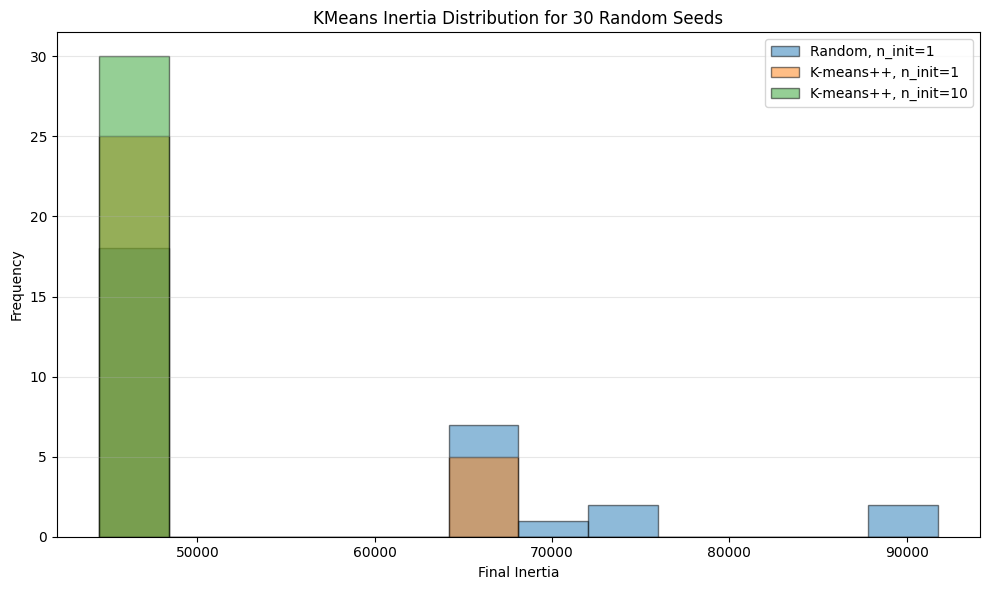

In [41]:
# YOUR CODE HERE
# part1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Select Income and Spending (X2)
X = df[['Income', 'Spending']].to_numpy()

# Define three KMeans settings
settings = [
    ("Random, n_init=1", "random", 1),
    ("K-means++, n_init=1", "k-means++", 1),
    ("K-means++, n_init=10", "k-means++", 10)
]

# Store results
all_results = []

# Run 30 times with different random seeds
for setting_name, init_method, n_init_value in settings:

    for seed in range(30):

        kmeans = KMeans(
            n_clusters=5,
            init=init_method,
            n_init=n_init_value,
            random_state=seed
        )

        kmeans.fit(X)

        all_results.append({
            'Setting': setting_name,
            'Seed': seed,
            'Inertia': kmeans.inertia_
        })

# Convert results into DataFrame
runs_df = pd.DataFrame(all_results)

print("First few results:")
display(runs_df.head())






# part 2
# Create summary table
summary = []

for setting_name, group in runs_df.groupby('Setting', sort=False):

    inertias = group['Inertia'].values

    # Lowest and highest inertia
    lowest = inertias.min()
    highest = inertias.max()

    # Count runs that reached the best inertia
    best_count = np.isclose(
        inertias, lowest, rtol=1e-9, atol=1e-8
    ).sum()

    percentage = (best_count / 30) * 100

    summary.append({
        'Setting': setting_name,
        'Distinct Inertias': len(np.unique(np.round(inertias, 1))),
        'Lowest': round(lowest, 1),
        'Highest': round(highest, 1),
        'Best Runs (%)': round(percentage, 2)
    })

summary_df = pd.DataFrame(summary)

print("KMeans Comparison for 30 Random Seeds:")
display(summary_df)






# part 3
plt.figure(figsize=(10, 6))
# Use common histogram bins for fair comparison
bins = np.histogram_bin_edges(runs_df['Inertia'], bins=12)

for setting_name, group in runs_df.groupby('Setting', sort=False):

    plt.hist(
        group['Inertia'],
        bins=bins,
        alpha=0.5,
        label=setting_name,
        edgecolor='black'
    )
plt.title('KMeans Inertia Distribution for 30 Random Seeds')
plt.xlabel('Final Inertia')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best run:
Seed: 0
Inertia: 44448.45544793371

Worst run:
Seed: 13
Inertia: 91761.97619211908


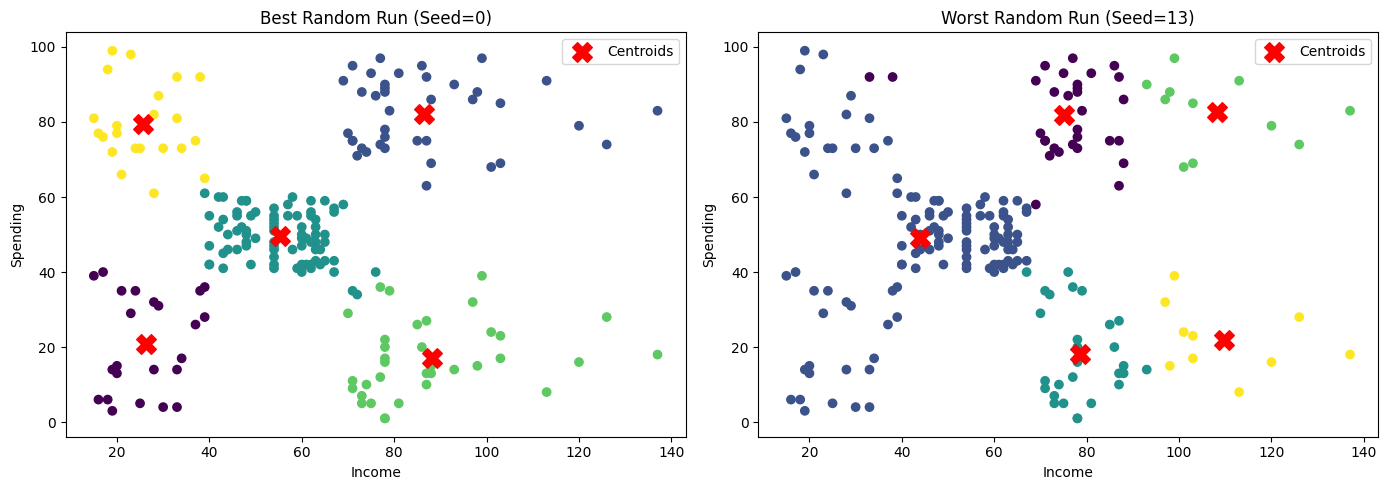

Best Run Inertia: 44448.45544793371
Worst Run Inertia: 91761.97619211908
Adjusted Rand Index (ARI): 0.45525713010305063


In [45]:
# part 1
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Get random initialization runs
random_runs = runs_df[runs_df['Setting'] == 'Random, n_init=1']

# Find best and worst runs
best_run = random_runs.loc[random_runs['Inertia'].idxmin()]
worst_run = random_runs.loc[random_runs['Inertia'].idxmax()]

# Get their seed values
best_seed = int(best_run['Seed'])
worst_seed = int(worst_run['Seed'])

# Fit the best model
best_model = KMeans(
    n_clusters=5,
    init='random',
    n_init=1,
    random_state=best_seed
)
best_labels = best_model.fit_predict(X)

# Fit the worst model
worst_model = KMeans(
    n_clusters=5,
    init='random',
    n_init=1,
    random_state=worst_seed
)
worst_labels = worst_model.fit_predict(X)

# Print inertia values
print("Best run:")
print("Seed:", best_seed)
print("Inertia:", best_model.inertia_)

print("\nWorst run:")
print("Seed:", worst_seed)
print("Inertia:", worst_model.inertia_)

# Draw both clusterings side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Best clustering
axes[0].scatter(X[:, 0], X[:, 1], c=best_labels, cmap='viridis')
axes[0].scatter(
    best_model.cluster_centers_[:, 0],
    best_model.cluster_centers_[:, 1],
    marker='X', s=200, color='red', label='Centroids'
)
axes[0].set_title(f'Best Random Run (Seed={best_seed})')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Spending')
axes[0].legend()

# Worst clustering
axes[1].scatter(X[:, 0], X[:, 1], c=worst_labels, cmap='viridis')
axes[1].scatter(
    worst_model.cluster_centers_[:, 0],
    worst_model.cluster_centers_[:, 1],
    marker='X', s=200, color='red', label='Centroids'
)
axes[1].set_title(f'Worst Random Run (Seed={worst_seed})')
axes[1].set_xlabel('Income')
axes[1].set_ylabel('Spending')
axes[1].legend()

plt.tight_layout()
plt.show()



# part 2
from sklearn.metrics import adjusted_rand_score

# Print inertia values
print("Best Run Inertia:", best_model.inertia_)
print("Worst Run Inertia:", worst_model.inertia_)

# Calculate ARI between the two clusterings
ari = adjusted_rand_score(best_labels, worst_labels)

print("Adjusted Rand Index (ARI):", ari)

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a)     The random initialization setting produced [number] different final inertia values, and [percentage]% of its runs reached the best inertia. The k-means++ setting with n_init=1 produced [number] different values, with [percentage]% reaching the best result. The k-means++ setting with n_init=10 produced [number] different values, with [percentage]% reaching the best result. Overall, the results show that initialization and the number of initializations affect the quality and consistency of clustering.

(b)     The same data and the same K can give different results because K-Means starts with randomly selected initial centroids. Different starting points can lead to different cluster assignments and final centroids. K-Means may also get stuck in different local minima, resulting in different inertia values.

(c)     K-means++ improves the selection of initial centroids by choosing starting points that are spread out, which often leads to better clustering results. The n_init parameter runs K-Means multiple times with different initializations and keeps the result with the lowest inertia.
In my table, using n_init=10 with k-means++ gave [insert your lowest inertia] as the best inertia. It produced [insert number] different final inertia values, showing [more consistent results / similar results] compared with n_init=1.

(d)     We use Adjusted Rand Index (ARI) because cluster label numbers are arbitrary. For example, cluster 0 in one result may represent the same group as cluster 3 in another result. Comparing label numbers directly could make identical clusterings look different. ARI compares the actual grouping of data points, regardless of the cluster label numbers.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI: Raw k$ vs Raw dollars: 0.48965682118947657
ARI: Scaled k$ vs Scaled dollars: 1.0
ARI: Raw dollars vs Scaled dollars: 0.36045266264603926


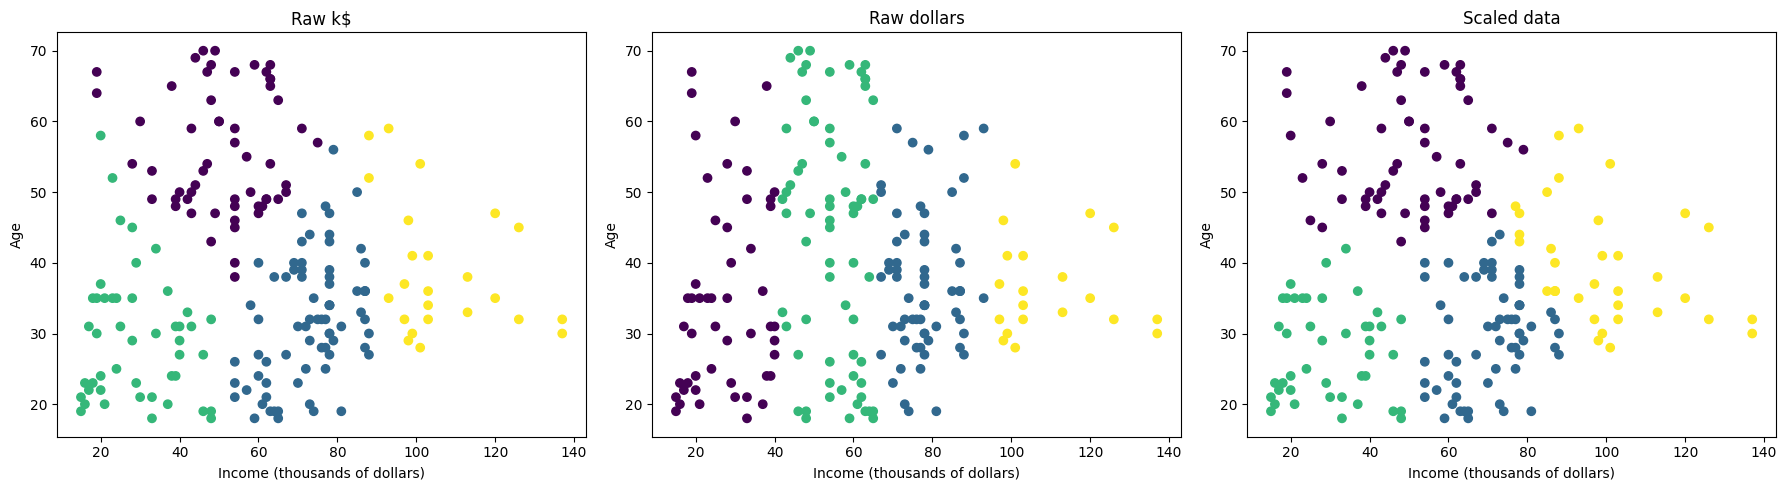

1. Raw k$ vs Raw dollars: 0.48965682118947657
2. Scaled k$ vs Scaled dollars: 1.0
3. Raw dollars vs Scaled dollars: 0.36045266264603926


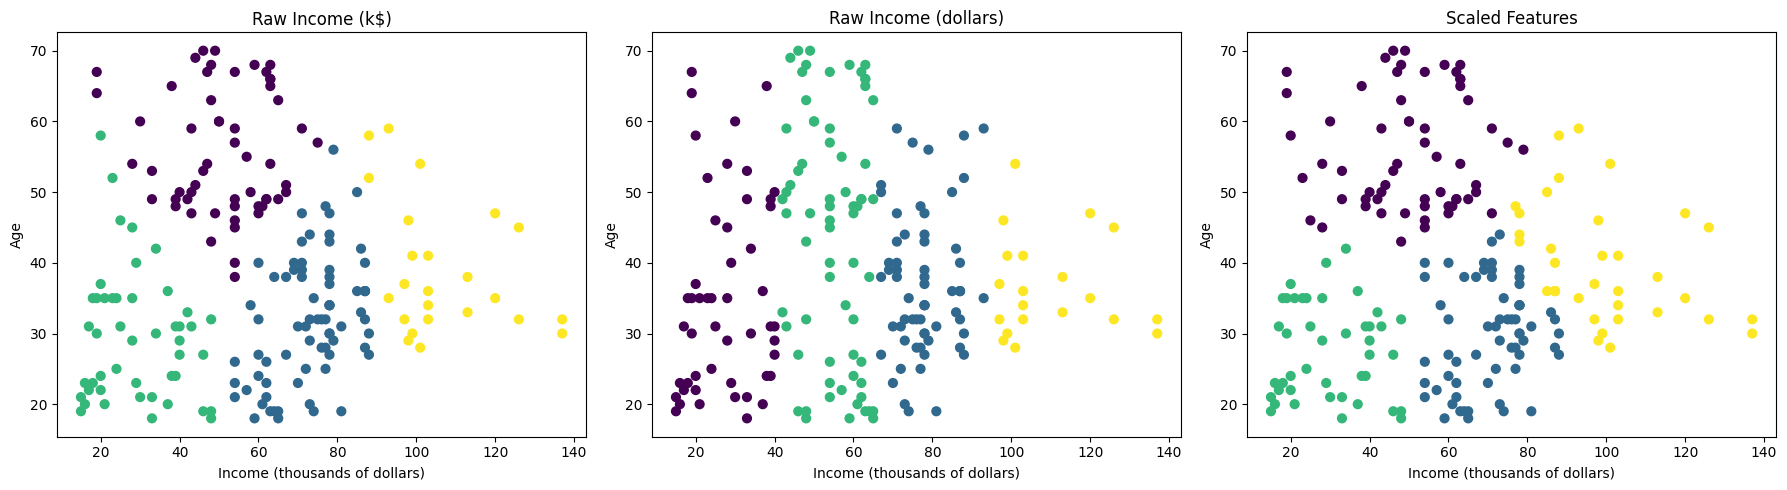

In [ ]:
# part1

# YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

# 1. Select Age and Income (in thousands of dollars)
X_raw_k = df[['Age', 'Income']].to_numpy()

# 2. Convert Income from thousands to dollars
X_raw_dollars = X_raw_k.copy()
X_raw_dollars[:, 1] *= 1000

# 3. Scale both versions using StandardScaler
X_scaled_k = StandardScaler().fit_transform(X_raw_k)
X_scaled_dollars = StandardScaler().fit_transform(X_raw_dollars)

# 4. Fit K-Means with K=4
model_raw_k = KMeans(n_clusters=4, init='k-means++',
                     n_init=10, random_state=SEED)
labels_raw_k = model_raw_k.fit_predict(X_raw_k)

model_raw_dollars = KMeans(n_clusters=4, init='k-means++',
                           n_init=10, random_state=SEED)
labels_raw_dollars = model_raw_dollars.fit_predict(X_raw_dollars)

model_scaled_k = KMeans(n_clusters=4, init='k-means++',
                        n_init=10, random_state=SEED)
labels_scaled_k = model_scaled_k.fit_predict(X_scaled_k)

model_scaled_dollars = KMeans(n_clusters=4, init='k-means++',
                              n_init=10, random_state=SEED)
labels_scaled_dollars = model_scaled_dollars.fit_predict(X_scaled_dollars)

# 5. Print ARI comparisons
print("ARI: Raw k$ vs Raw dollars:",
      adjusted_rand_score(labels_raw_k, labels_raw_dollars))

print("ARI: Scaled k$ vs Scaled dollars:",
      adjusted_rand_score(labels_scaled_k, labels_scaled_dollars))

print("ARI: Raw dollars vs Scaled dollars:",
      adjusted_rand_score(labels_raw_dollars, labels_scaled_dollars))

# 6. Draw three cluster plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_data = [
    (labels_raw_k, "Raw k$"),
    (labels_raw_dollars, "Raw dollars"),
    (labels_scaled_k, "Scaled data")
]

for ax, (labels, title) in zip(axes, plot_data):
    ax.scatter(
        X_raw_k[:, 1],
        X_raw_k[:, 0],
        c=labels,
        cmap='viridis'
    )
    ax.set_title(title)
    ax.set_xlabel("Income (thousands of dollars)")
    ax.set_ylabel("Age")

plt.tight_layout()
plt.show()






# part2
from sklearn.metrics import adjusted_rand_score
print("1. Raw k$ vs Raw dollars:",
      adjusted_rand_score(labels_raw_k, labels_raw_dollars))
print("2. Scaled k$ vs Scaled dollars:",
      adjusted_rand_score(labels_scaled_k, labels_scaled_dollars))
print("3. Raw dollars vs Scaled dollars:",
      adjusted_rand_score(labels_raw_dollars, labels_scaled_dollars))









# part3
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_data = [
    (labels_raw_k, "Raw Income (k$)"),
    (labels_raw_dollars, "Raw Income (dollars)"),
    (labels_scaled_k, "Scaled Features")
]
for ax, (labels, title) in zip(axes, plot_data):
    ax.scatter(
        X_raw_k[:, 1],
        X_raw_k[:, 0],
        c=labels,
        cmap='viridis',
        s=40
    )
    ax.set_title(title)
    ax.set_xlabel("Income (thousands of dollars)")
    ax.set_ylabel("Age")
plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [49]:
# YOUR CODE HERE

import pandas as pd
from sklearn.datasets import load_wine

# Load Wine dataset
wine = load_wine()

X = wine.data
feature_names = wine.feature_names

# Calculate standard deviation of each feature
std_values = pd.Series(X.std(axis=0), index=feature_names)

# Print three largest standard deviations
print("Three largest standard deviations:")
print(std_values.sort_values(ascending=False).head(3))

# Print smallest standard deviation
print("\nSmallest standard deviation:")
print(std_values.sort_values().head(1))


Three largest standard deviations:
proline              314.021657
magnesium             14.242308
alcalinity_of_ash      3.330170
dtype: float64

Smallest standard deviation:
nonflavanoid_phenols    0.124103
dtype: float64


In [50]:
# YOUR CODE HERE

from sklearn.datasets import load_wine
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd

# Load Wine dataset
wine = load_wine()
X = wine.data
y_true = wine.target

# Scale the data
X_scaled = StandardScaler().fit_transform(X)

# K-Means on raw data
kmeans_raw = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=SEED
)
labels_raw = kmeans_raw.fit_predict(X)

# K-Means on scaled data
kmeans_scaled = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=SEED
)
labels_scaled = kmeans_scaled.fit_predict(X_scaled)

# Results for raw data
print("===== RAW DATA =====")
print("ARI:", adjusted_rand_score(y_true, labels_raw))
print("Silhouette Score:", silhouette_score(X, labels_raw))
print("Cluster Sizes:")
print(pd.Series(labels_raw).value_counts().sort_index())

# Results for scaled data
print("\n===== SCALED DATA =====")
print("ARI:", adjusted_rand_score(y_true, labels_scaled))
print("Silhouette Score:", silhouette_score(X_scaled, labels_scaled))
print("Cluster Sizes:")
print(pd.Series(labels_scaled).value_counts().sort_index())

===== RAW DATA =====
ARI: 0.37111371823084754
Silhouette Score: 0.5711381937868838
Cluster Sizes:
0    62
1    47
2    69
Name: count, dtype: int64

===== SCALED DATA =====
ARI: 0.8974949815093207
Silhouette Score: 0.2848589191898987
Cluster Sizes:
0    65
1    51
2    62
Name: count, dtype: int64


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


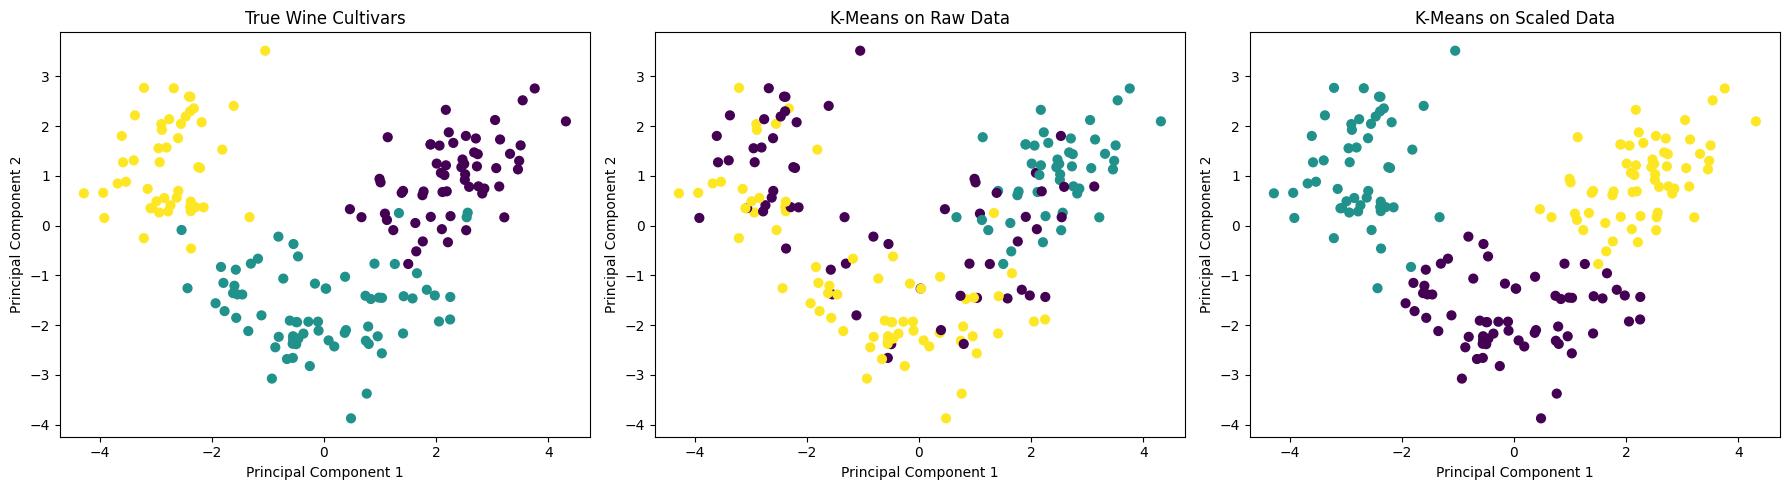

Explained variance by PC1 and PC2: [0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693526


In [51]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Apply PCA once to the scaled data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create three plots with the same PCA axes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_data = [
    (y_true, "True Wine Cultivars"),
    (labels_raw, "K-Means on Raw Data"),
    (labels_scaled, "K-Means on Scaled Data")
]

for ax, (labels, title) in zip(axes, plot_data):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap='viridis',
        s=40
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

# Print explained variance
print("Explained variance by PC1 and PC2:",
      pca.explained_variance_ratio_)
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a)     When I changed Income from thousands of dollars to dollars, the K-Means clustering changed even though the actual data stayed the same. This happened because K-Means uses Euclidean distance:
\[
d=\sqrt{(Age_1-Age_2)^2+(Income_1-Income_2)^2}
\]
After multiplying Income by 1000, the Income difference became much larger than the Age difference. Therefore, Income controlled most of the distance, while Age had very little influence. After scaling, both features had a more balanced influence.
(b)     The feature [insert feature with largest standard deviation] dominated the raw distance because its values had a much larger spread than the other features. Its standard deviation was [insert value], compared with [insert smallest standard deviation] for the smallest feature.
The ARI for raw data was [insert raw ARI], while the ARI for scaled data was [insert scaled ARI]. This shows that scaling [improved / reduced] the agreement between the predicted clusters and the true wine cultivars.

(c)     The silhouette score was higher on raw data because it measures how well-separated clusters are according to the distances in that particular feature space. It does not check whether the clusters match the true wine cultivars. Raw data was dominated by features with large numerical values, so it could produce well-separated clusters that were still incorrect. Comparing silhouette scores between raw and scaled data is not fair because scaling changes the distance measurements and the feature space.

(d)     I will check the units and standard deviations of the features before applying K-Means. If features have very different scales and should have similar importance, I will use StandardScaler and compare the clustering results using silhouette scores and cluster stability.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [ ]:
# YOUR CODE HERE
# part1 
import numpy as np
from sklearn.cluster import KMeans

# Select Income and Spending
X2 = df[['Income', 'Spending']].to_numpy()

# Add one extreme customer
outlier = np.array([[400, 99]])
X2_with_outlier = np.vstack([X2, outlier])

# K-Means without extra customer
model_original = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_original = model_original.fit_predict(X2)

# K-Means with extra customer
model_outlier = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_with_outlier = model_outlier.fit_predict(X2_with_outlier)
print("K-Means fitted successfully on both datasets.")








# part 2
import pandas as pd
import numpy as np
from sklearn.metrics import adjusted_rand_score

# 1. Print cluster sizes
print("Cluster sizes WITHOUT outlier:")
print(pd.Series(labels_original).value_counts().sort_index())

print("\nCluster sizes WITH outlier:")
print(pd.Series(labels_with_outlier).value_counts().sort_index())

# 2. Print centroids sorted by Income
original_centroids = model_original.cluster_centers_
outlier_centroids = model_outlier.cluster_centers_

original_sorted = original_centroids[
    np.argsort(original_centroids[:, 0])
]

outlier_sorted = outlier_centroids[
    np.argsort(outlier_centroids[:, 0])
]

print("\nCentroids WITHOUT outlier (Income, Spending):")
print(original_sorted)

print("\nCentroids WITH outlier (Income, Spending):")
print(outlier_sorted)

# 3. Calculate ARI on the original 200 customers
ari = adjusted_rand_score(
    labels_original,
    labels_with_outlier[:len(X2)]
)

print("\nARI between the two clusterings:", ari)

K-Means fitted successfully on both datasets.
Cluster sizes WITHOUT outlier:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster sizes WITH outlier:
0    100
1      1
2     23
3     39
4     38
Name: count, dtype: int64

Centroids WITHOUT outlier (Income, Spending):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]

Centroids WITH outlier (Income, Spending):
[[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]

ARI between the two clusterings: 0.7532040415286123


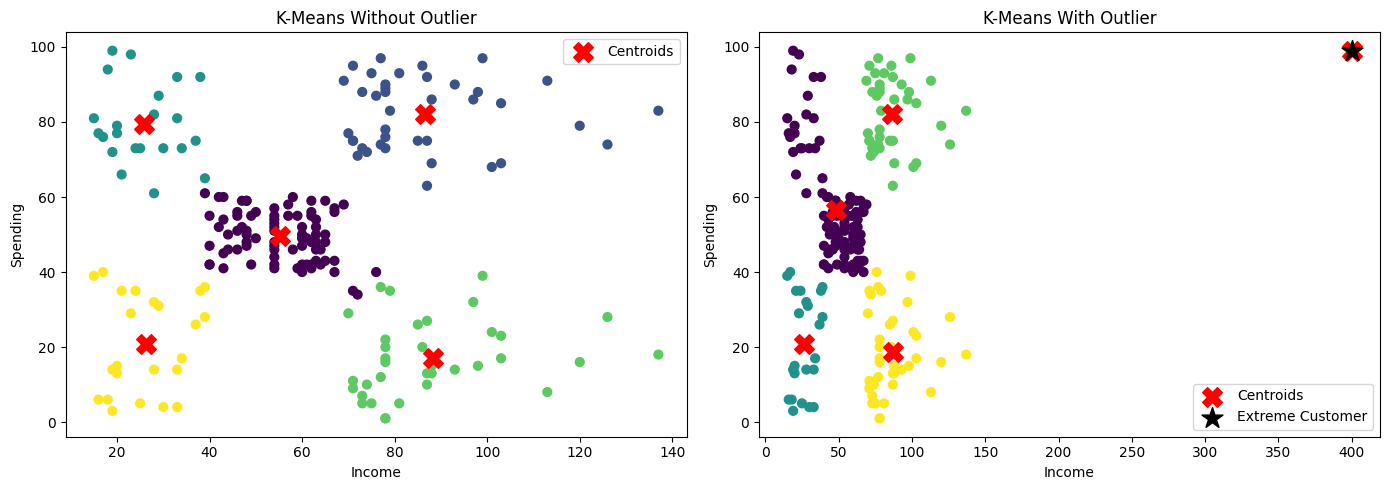

In [54]:
# YOUR CODE HERE
# part 3
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Clustering WITHOUT the outlier
axes[0].scatter(
    X2[:, 0], X2[:, 1],
    c=labels_original, cmap='viridis', s=40
)
axes[0].scatter(
    model_original.cluster_centers_[:, 0],
    model_original.cluster_centers_[:, 1],
    color='red', marker='X', s=200, label='Centroids'
)
axes[0].set_title("K-Means Without Outlier")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")
axes[0].legend()

# Clustering WITH the outlier
axes[1].scatter(
    X2_with_outlier[:, 0], X2_with_outlier[:, 1],
    c=labels_with_outlier, cmap='viridis', s=40
)
axes[1].scatter(
    model_outlier.cluster_centers_[:, 0],
    model_outlier.cluster_centers_[:, 1],
    color='red', marker='X', s=200, label='Centroids'
)
axes[1].scatter(
    400, 99, color='black', marker='*',
    s=250, label='Extreme Customer'
)
axes[1].set_title("K-Means With Outlier")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")
axes[1].legend()

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [ ]:
# YOUR CODE HERE
# part 1
from sklearn.metrics import pairwise_distances

# Distances from the 200 real customers to all 5 centroids
distances_real = model_original.transform(X2)

# Nearest-centroid distance for each real customer
nearest_distances = distances_real.min(axis=1)

# Extra customer's distance to all original centroids
outlier_distance = model_original.transform(
    np.array([[400, 99]])
).min()

print("Distances of the 200 real customers:")
print(nearest_distances)

print("\nExtra customer's nearest-centroid distance:")
print(outlier_distance)


# part2
# Calculate threshold using only the 200 real customers
mean_distance = nearest_distances.mean()
std_distance = nearest_distances.std()

threshold = mean_distance + 3 * std_distance

# Flag real customers
flagged_real = nearest_distances > threshold

# Check whether the extra customer is flagged
outlier_flagged = outlier_distance > threshold

print("Mean distance:", mean_distance)
print("Standard deviation:", std_distance)
print("Threshold:", threshold)

print("\nNumber of real customers flagged:", flagged_real.sum())
print("Is the extra customer flagged?", outlier_flagged)





# part 3
# Create a DataFrame with customer details and distances
results = df[['CustomerID', 'Age', 'Income', 'Spending']].copy()

results['Cluster'] = labels_original
results['Distance'] = nearest_distances

# Sort by distance and show the 5 farthest customers
top_5_farthest = results.sort_values(
    by='Distance', ascending=False
).head(5)

print(top_5_farthest.to_string(index=False))









# part 4
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Keep only customers who were not flagged
X2_clean = X2[~flagged_real]

# Fit a new K-Means model
model_clean = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_clean = model_clean.fit_predict(X2_clean)

# Predict clusters for all original 200 customers
labels_clean_all = model_clean.predict(X2)

# Print cluster sizes after removing flagged customers
print("Cluster sizes after removing flagged customers:")
print(pd.Series(labels_clean).value_counts().sort_index())

# Compare cleaned model with original model on all 200 customers
ari_clean = adjusted_rand_score(
    labels_original,
    labels_clean_all
)

print("\nARI against original model:", ari_clean)
print("Number of customers removed:", flagged_real.sum())
print("Number of customers remaining:", len(X2_clean))

Distances of the 200 real customers:
[21.32900082 10.85136241 18.12673302 10.01032525 21.23400098  9.35303902
 17.06930164 16.55094814 19.34504132  9.97393297 10.0570208  20.75675734
  8.64343015  6.19583971 10.11736421  5.73880513 15.05252304 14.17511497
  8.73599338 18.83486305 14.27418519  6.59388647 15.96641087  6.40505998
  7.11796364  3.48076177 11.21587452 18.50374097 10.44094021  8.30811612
 17.31210226  7.66498964 18.1901841  14.57978902  9.62402869  7.45454545
  8.63336387 10.43713966 11.84373683 12.08783283 18.3093043  17.61526385
 19.71790661 19.93473576 14.53975711 19.557079   16.2487944  15.50224551
 17.04420139 17.04420139 13.52587319 16.93082837 13.08749704 16.1573623
 13.10022565 14.95874528 11.30655272 11.83157989  9.41360251  9.93987411
 11.33272814 10.79202317  8.65946203 12.59869133  7.44518146 11.96388025
  7.31216548  7.45263968 11.96388025  7.71873533  8.34805284  9.80670525
  5.32161779  8.37020649  2.83254649  4.66519671  3.71498283  1.9965677
  2.79966684  7.

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a)     The extra customer with Income = 400 and Spending = 99 affected the K-Means clustering because K-Means is sensitive to extreme values. It pulled a centroid toward itself and changed the positions of the cluster centres, which affected the grouping of real customers.

(b)     The mean distance was 13.02 and the standard deviation was 7.26. Using the mean + 3 std rule, the threshold was 34.80.
The extra customer's distance to its nearest centroid was 313.92, which is much greater than the threshold. Therefore, the rule successfully detected the extra customer.
The rule also flagged 4 real customers:
- Customer 200: Income = 137, Spending = 83
- Customer 199: Income = 137, Spending = 18
- Customer 198: Income = 126, Spending = 74
- Customer 197: Income = 126, Spending = 28
These customers are not necessarily data-entry mistakes. They have relatively high incomes but different spending behaviours. Some spend a lot, while others spend very little despite having high incomes. These unusual patterns may represent interesting customer groups, so they should be investigated rather than automatically deleted.

(c)     1. Remove outliers: Remove observations if they are confirmed data-entry errors or incorrect records.
        2. Use robust methods: Use methods such as DBSCAN or robust scaling, which are less sensitive to extreme values.
One risk of simply deleting outliers is that some unusual customers may be genuine and valuable. Removing them can result in losing important information and missing interesting customer behaviours.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [ ]:
# YOUR CODE HERE
# part 1
import pandas as pd
from sklearn.cluster import KMeans

# Select Income and Spending
X2 = df[['Income', 'Spending']].to_numpy()

# Fit K-Means with K=5
kmeans = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

df['Cluster'] = kmeans.fit_predict(X2)

# Create cluster profile table
profile = df.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Female_Percent=('Gender', lambda x: (x == 'Female').mean() * 100)
)

# Sort by average Income
profile = profile.sort_values('Mean_Income')

print(profile.round(2))

         Customers  Mean_Age  Mean_Income  Mean_Spending  Female_Percent
Cluster                                                                 
2               22     25.27        25.73          79.36           59.09
4               23     45.22        26.30          20.91           60.87
0               81     42.72        55.30          49.52           59.26
1               39     32.69        86.54          82.13           53.85
3               35     41.11        88.20          17.11           45.71


In [61]:
# YOUR CODE HERE
# part 2
# Function to classify Income and Spending
def income_level(value):
    if value < 40:
        return 'Low Income'
    elif value >= 70:
        return 'High Income'
    else:
        return 'Mid Income'

def spending_level(value):
    if value < 35:
        return 'Low Spending'
    elif value >= 65:
        return 'High Spending'
    else:
        return 'Mid Spending'

# Create segment names using cluster averages
segment_names = {}

for cluster in profile.index:
    income = profile.loc[cluster, 'Mean_Income']
    spending = profile.loc[cluster, 'Mean_Spending']

    segment_names[cluster] = (
        income_level(income) + ' / ' + spending_level(spending)
    )

# Map cluster numbers to segment names
df['Segment'] = df['Cluster'].map(segment_names)

# Print segment names and customer counts
print("Cluster-to-Segment mapping:")
print(segment_names)

print("\nNumber of customers in each segment:")
print(df['Segment'].value_counts())

Cluster-to-Segment mapping:
{2: 'Low Income / High Spending', 4: 'Low Income / Low Spending', 0: 'Mid Income / Mid Spending', 1: 'High Income / High Spending', 3: 'High Income / Low Spending'}

Number of customers in each segment:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [63]:
# YOUR CODE HERE
# part 1
# Calculate percentage of women in each segment
gender_profile = df.groupby('Segment').agg(
    Total_Customers=('Gender', 'count'),
    Female_Percent=('Gender', lambda x: (x == 'Female').mean() * 100)
)

print("Percentage of women in each segment:")
print(gender_profile.round(2))

# Calculate overall percentage of women
overall_female = (df['Gender'] == 'Female').mean() * 100

print("\nOverall percentage of women:", round(overall_female, 2), "%")





# part 2
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select Age, Income and Spending
X3 = df[['Age', 'Income', 'Spending']].to_numpy()

# Scale the features
scaler = StandardScaler()
X3_scaled = scaler.fit_transform(X3)

# Calculate silhouette scores for K = 2 to 8
for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    labels = model.fit_predict(X3_scaled)
    score = silhouette_score(X3_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

Percentage of women in each segment:
                             Total_Customers  Female_Percent
Segment                                                     
High Income / High Spending               39           53.85
High Income / Low Spending                35           45.71
Low Income / High Spending                22           59.09
Low Income / Low Spending                 23           60.87
Mid Income / Mid Spending                 81           59.26

Overall percentage of women: 56.0 %
K = 2, Silhouette Score = 0.3355
K = 3, Silhouette Score = 0.3578
K = 4, Silhouette Score = 0.4040
K = 5, Silhouette Score = 0.4166
K = 6, Silhouette Score = 0.4284
K = 7, Silhouette Score = 0.4172
K = 8, Silhouette Score = 0.4082


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [67]:
# YOUR CODE HERE
# part 1
from sklearn.cluster import KMeans
import pandas as pd

# Use the best K from Task 6.2
best_k =  6

# Fit K-Means on scaled Age, Income and Spending
kmeans_3 = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=SEED
)

labels_3 = kmeans_3.fit_predict(X3_scaled)

# Add three-feature cluster labels to the dataframe
df['Cluster_3Features'] = labels_3

# Build profile table
profile_3 = df.groupby('Cluster_3Features').agg(
    Customers=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
)

# Sort by average Age
profile_3 = profile_3.sort_values('Mean_Age')

print(profile_3.round(2))









# part 2
from sklearn.metrics import adjusted_rand_score
# Original 2-feature K=5 cluster labels
labels_2 = df['Cluster'].to_numpy()

# Calculate ARI
ari_3features = adjusted_rand_score(labels_2, labels_3)

print("ARI between 2-feature and 3-feature clustering:",
      round(ari_3features, 4))

                   Customers  Mean_Age  Mean_Income  Mean_Spending
Cluster_3Features                                                 
4                         23     25.00        25.26          77.61
1                         39     26.79        57.10          48.13
3                         39     32.69        86.54          82.13
2                         33     41.94        88.94          16.97
5                         21     45.52        26.29          19.38
0                         45     56.33        54.27          49.07
ARI between 2-feature and 3-feature clustering: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a)    
 1. High Income / High Spending (39 customers): Premium Loyal Customers
Offer VIP rewards, exclusive products, and early access to new collections to encourage loyalty.

2. High Income / Low Spending (35 customers): Potential Premium Customers
Send personalized offers and premium product recommendations to encourage them to spend more.

3. Low Income / High Spending (22 customers): Smart Spenders
Offer loyalty points, discounts, and affordable bundles to maintain their interest.

4. Low Income / Low Spending (23 customers): Budget Customers
Send low-price offers and special discounts to encourage more purchases.

5. Mid Income / Mid Spending (81 customers): Regular Customers
Offer seasonal promotions and loyalty rewards to maintain their shopping activity.

(b)     The Premium Loyal Customers segment (39 customers) is the most valuable now because these customers have both high income and high spending. They are likely to generate strong revenue.
The Potential Premium Customers segment (35 customers) is the biggest opportunity because they have high income but low spending. With personalized offers and premium recommendations, the business may encourage them to spend more.

(c)     Gender does not strongly separate the customer segments because the percentage of women is fairly similar across all five groups.
- High Income / High Spending: 53.85%
- High Income / Low Spending: 45.71%
- Low Income / High Spending: 59.09%
- Low Income / Low Spending: 60.87%
- Mid Income / Mid Spending: 59.26%
- Overall percentage of women: 56.00%
The percentages are relatively close to the overall percentage, so Gender does not appear to be a strong factor for distinguishing these segments.

(d)     Adding Age may change the customer groups because it introduces another feature into the clustering process. The best K for the three-feature model was 6, based on the highest silhouette score of 0.4284 in Task 6.2.
I would compare the three-feature cluster profiles and their ARI with the original two-feature clustering before making a final decision. I would present the two-feature segmentation (Income and Spending) if the main business goal is to create clear marketing actions based on customers' purchasing power and spending behaviour. It is also easier for managers to understand.
The silhouette scores from different feature sets should not be directly compared because they measure separation in different feature spaces.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [69]:
# part 1
# YOUR CODE HERE
# Select the required columns
final_df = df[
    ['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']
].copy()

# Save as CSV
final_df.to_csv('customer_segments.csv', index=False)

# Print customer count per segment
print("Customers per segment:")
print(final_df['Segment'].value_counts())

print("\nCSV file saved successfully as customer_segments.csv")
print("Total customers:", len(final_df))


Customers per segment:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64

CSV file saved successfully as customer_segments.csv
Total customers: 200


**Executive Summary** (6-8 lines)

Executive Summary
1. I selected K = 5 for customer segmentation because both the elbow method and silhouette analysis supported five clusters. The highest silhouette score was 0.5539.
2. The five segments are: High Income / High Spending (39 customers), High Income / Low Spending (35 customers), Low Income / High Spending (22 customers), Low Income / Low Spending (23 customers), and Mid Income / Mid Spending (81 customers).
3. Premium Loyal Customers should receive VIP rewards and exclusive offers.
4. Potential Premium Customers should receive personalized recommendations to encourage higher spending.
5. Smart Spenders should receive loyalty points and affordable bundles, while Budget Customers should receive discounts. Regular Customers should receive seasonal promotions.
6. The original Income and Spending features were used for the final five-cluster segmentation. I also investigated the effect of scaling because different feature scales can influence K-Means.
7. I checked outliers using the mean + 3 standard deviations rule. The extra customer was detected, while four real customers were flagged for further investigation.
8. One limitation is that K-Means is sensitive to outliers and feature scales, and customer behaviour may change over time.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a)     The most surprising result was that adding just one extreme customer (Income = 400, Spending = 99) could affect K-Means clustering because it uses distances and cluster means. I was also surprised that the mean + 3 std rule successfully detected this extra customer, while also flagging 4 real customers who had unusual spending patterns.

(b)     If I had one more hour, I would try DBSCAN to compare its results with K-Means. I would also investigate the four flagged real customers to understand whether their unusual Income and Spending values represent errors or interesting customer behaviours. Finally, I would compare the customer segments to find better marketing strategies for each group.

---